In [1]:
# Chemins et manipulation des données
from pathlib import Path
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
from IPython.display import display

# Préparation des données
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import IsolationForest

# Modèle
from xgboost import XGBRegressor
from sklearn.base import clone

# Validation et recherche d'hyperparamètres
from sklearn.model_selection import (
    KFold,
    train_test_split,
    RandomizedSearchCV
)

# Évaluation
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Reproductibilité
RANDOM_STATE = 42
N_SPLITS = 5

pd.set_option("display.max_columns", 30)

In [2]:
# Dossier contenant les CSV du projet
DATA_DIR = Path("..")

# Charger les données originales avec leurs NaN
X_train_raw = pd.read_csv(DATA_DIR / "X_train.csv", index_col="id")
X_test_raw = pd.read_csv(DATA_DIR / "X_test.csv", index_col="id")
y_raw = pd.read_csv(DATA_DIR / "y_train.csv", index_col="id")["y"]

# Aligner les cibles sur les observations du train
y_raw = y_raw.loc[X_train_raw.index]

# Bilan des features
overview = pd.DataFrame({
    "observations": [len(X_train_raw), len(X_test_raw)],
    "features": [X_train_raw.shape[1], X_test_raw.shape[1]],
    "valeurs_manquantes": [
        X_train_raw.isna().sum().sum(),
        X_test_raw.isna().sum().sum()
    ],
    "NaN (%)": [
        100 * X_train_raw.isna().mean().mean(),
        100 * X_test_raw.isna().mean().mean()
    ]
}, index=["train", "test"])

display(overview.round(2))

print("IDs uniques :", X_train_raw.index.is_unique
      and X_test_raw.index.is_unique)
print("Cibles alignées :", X_train_raw.index.equals(y_raw.index))
print("Features identiques et dans le même ordre :",
      X_train_raw.columns.equals(X_test_raw.columns))
print("Cibles manquantes :", y_raw.isna().sum())

display(y_raw.describe().to_frame(name="âge"))

,observations,features,valeurs_manquantes,NaN (%)
train,1212,832,76902,7.63
test,776,832,40634,6.29


IDs uniques : True
Cibles alignées : True
Features identiques et dans le même ordre : True
Cibles manquantes : 0


,âge
count,1212.000000
mean,69.889439
std,9.720843
min,42.000000
25%,64.000000
50%,70.000000
75%,77.000000
max,97.000000


Traitement des colonnes constantes

In [3]:
# Nombre de valeurs distinctes par feature, en ignorant les NaN
n_unique = X_train_raw.nunique(dropna=True)

# Colonnes constantes ou entièrement manquantes
constant_cols = n_unique[n_unique <= 1].index.tolist()

display(pd.DataFrame({
    "valeurs_distinctes": n_unique.loc[constant_cols],
    "NaN (%)": (
        X_train_raw[constant_cols].isna().mean() * 100
    ).round(2)
}))

# Copies de travail : les NaN sont conservés
X_train = X_train_raw.drop(columns=constant_cols).copy()
X_test = X_test_raw.drop(columns=constant_cols).copy()
y_train = y_raw.copy()

print("Colonnes retirées :", constant_cols)
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

,valeurs_distinctes,NaN (%)
x104,1,6.85
x129,1,8.09
x489,1,8.25
x530,1,7.76


Colonnes retirées : ['x104', 'x129', 'x489', 'x530']
X_train : (1212, 828)
X_test  : (776, 828)


Visualisation des données avant de détecter les outliers 
On reprend l'approche PCA, en calculant cette fois 10 composantes 
Conservation des NaN 

,variance_expliquée (%),variance_cumulée (%),variance_test / variance_train
PC1,13.937,13.937,0.690
PC2,6.124,20.060,0.651
PC3,4.333,24.393,0.978
PC4,1.340,25.733,0.796
PC5,1.008,26.741,0.685
PC6,0.845,27.586,0.402
PC7,0.793,28.379,0.803
PC8,0.606,28.985,0.804
PC9,0.529,29.514,0.867
PC10,0.489,30.003,0.735


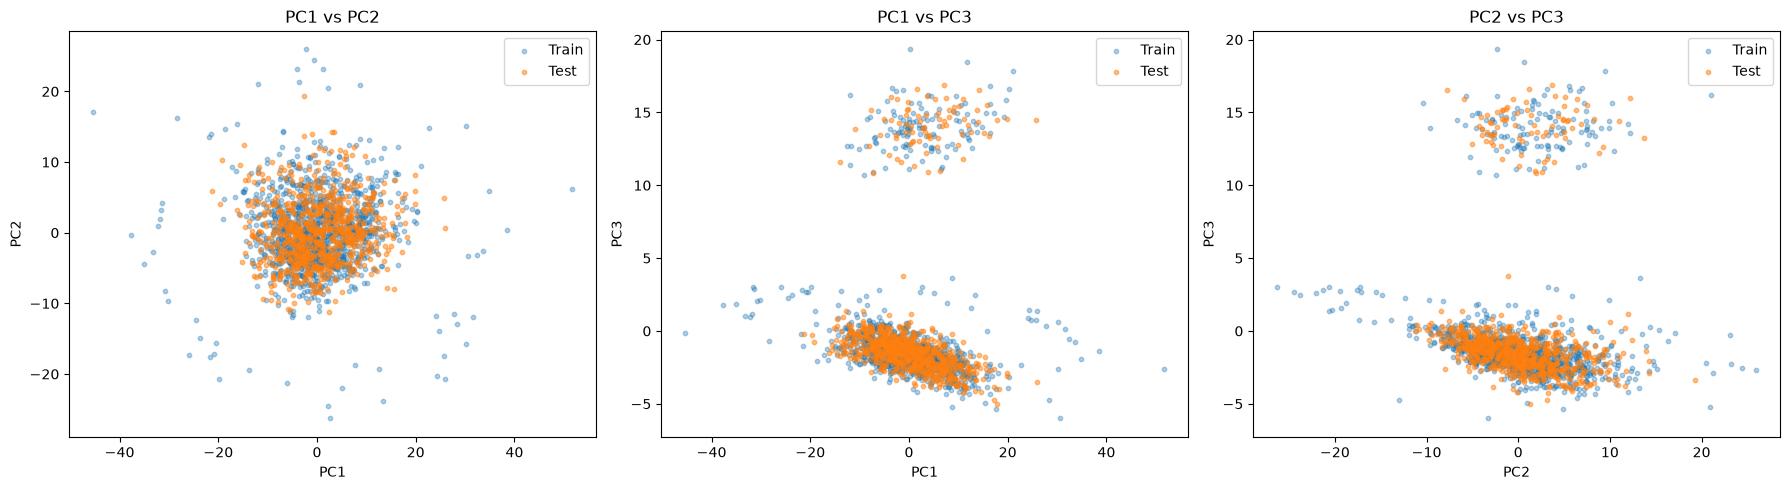

In [4]:
# Copies temporaires pour l'analyse des outliers
# Tous les ajustements sont faits sur le train
outlier_imputer = SimpleImputer(strategy="median") # remplir temporairement les NaN

X_train_diag = outlier_imputer.fit_transform(X_train)
X_test_diag = outlier_imputer.transform(X_test)

outlier_scaler = RobustScaler()
X_train_diag = outlier_scaler.fit_transform(X_train_diag)
X_test_diag = outlier_scaler.transform(X_test_diag)

# PCA exploratoire
pca_outliers = PCA(
    n_components=10,
    svd_solver="full"
)

P_train = pca_outliers.fit_transform(X_train_diag)
P_test = pca_outliers.transform(X_test_diag)

# Variance expliquée et dispersion train/test
variance = pd.DataFrame({
    "variance_expliquée (%)": (
        100 * pca_outliers.explained_variance_ratio_
    ),
    "variance_cumulée (%)": (
        100 * np.cumsum(pca_outliers.explained_variance_ratio_)
    ),
    "variance_test / variance_train": (
        P_test.var(axis=0) / P_train.var(axis=0)
    )
}, index=[f"PC{i + 1}" for i in range(10)])

display(variance.round(3))

# Visualiser les trois premières composantes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    ax.scatter(
        P_train[:, i], P_train[:, j],
        s=10, alpha=0.35, label="Train"
    )
    ax.scatter(
        P_test[:, i], P_test[:, j],
        s=10, alpha=0.5, label="Test"
    )
    ax.set(
        xlabel=f"PC{i + 1}",
        ylabel=f"PC{j + 1}",
        title=f"PC{i + 1} vs PC{j + 1}"
    )
    ax.legend()

plt.tight_layout()
plt.show()

In [5]:
# Résultats exploratoires : aucune observation n'est supprimée
outlier_scores = pd.DataFrame(index=X_train.index)
outlier_masks = pd.DataFrame(index=X_train.index)
comparison = []

for n_pc in [3, 6, 10]:
    # Mettre les composantes sur des échelles robustes comparables
    # Les paramètres d'échelle sont calculés uniquement sur le train
    pc_scaler = RobustScaler()

    Z_train = pc_scaler.fit_transform(P_train[:, :n_pc])
    Z_test = pc_scaler.transform(P_test[:, :n_pc])

    # Le test sert de référence pour les profils à prédire
    neighbors = NearestNeighbors(n_neighbors=6).fit(Z_test)

    # Train : distance au cinquième voisin dans le test
    train_distances = neighbors.kneighbors(
        Z_train, n_neighbors=5
    )[0][:, -1]

    # Test : distance au cinquième AUTRE voisin
    # Six voisins sont demandés car chaque point se retrouve lui-même
    test_distances = neighbors.kneighbors(
        Z_test, n_neighbors=6
    )[0][:, -1]

    # Même règle que dans le data prep initial
    threshold = np.quantile(test_distances, 0.995)

    name = f"{n_pc}_PC"
    outlier_scores[name] = train_distances
    outlier_masks[name] = train_distances > threshold

    comparison.append({
        "composantes": n_pc,
        "outliers_signalés": int(outlier_masks[name].sum()),
        "train_signalé (%)": 100 * outlier_masks[name].mean(),
        "test_au_dessus_du_seuil": int(
            (test_distances > threshold).sum()
        ),
        "désaccords_avec_3_PC": int(
            (outlier_masks[name] != outlier_masks["3_PC"]).sum()
        )
    })

comparison = pd.DataFrame(comparison).set_index("composantes")
display(comparison.round(2))

,outliers_signalés,train_signalé (%),test_au_dessus_du_seuil,désaccords_avec_3_PC
composantes,,,,
3,60,4.95,4,0
6,34,2.81,4,56
10,18,1.49,4,66


,groupe,observations
0,Non signalé,1137
1,Signalé uniquement en 3 PC,41
2,Signalé uniquement en 6 PC,15
3,Signalé dans les deux,19


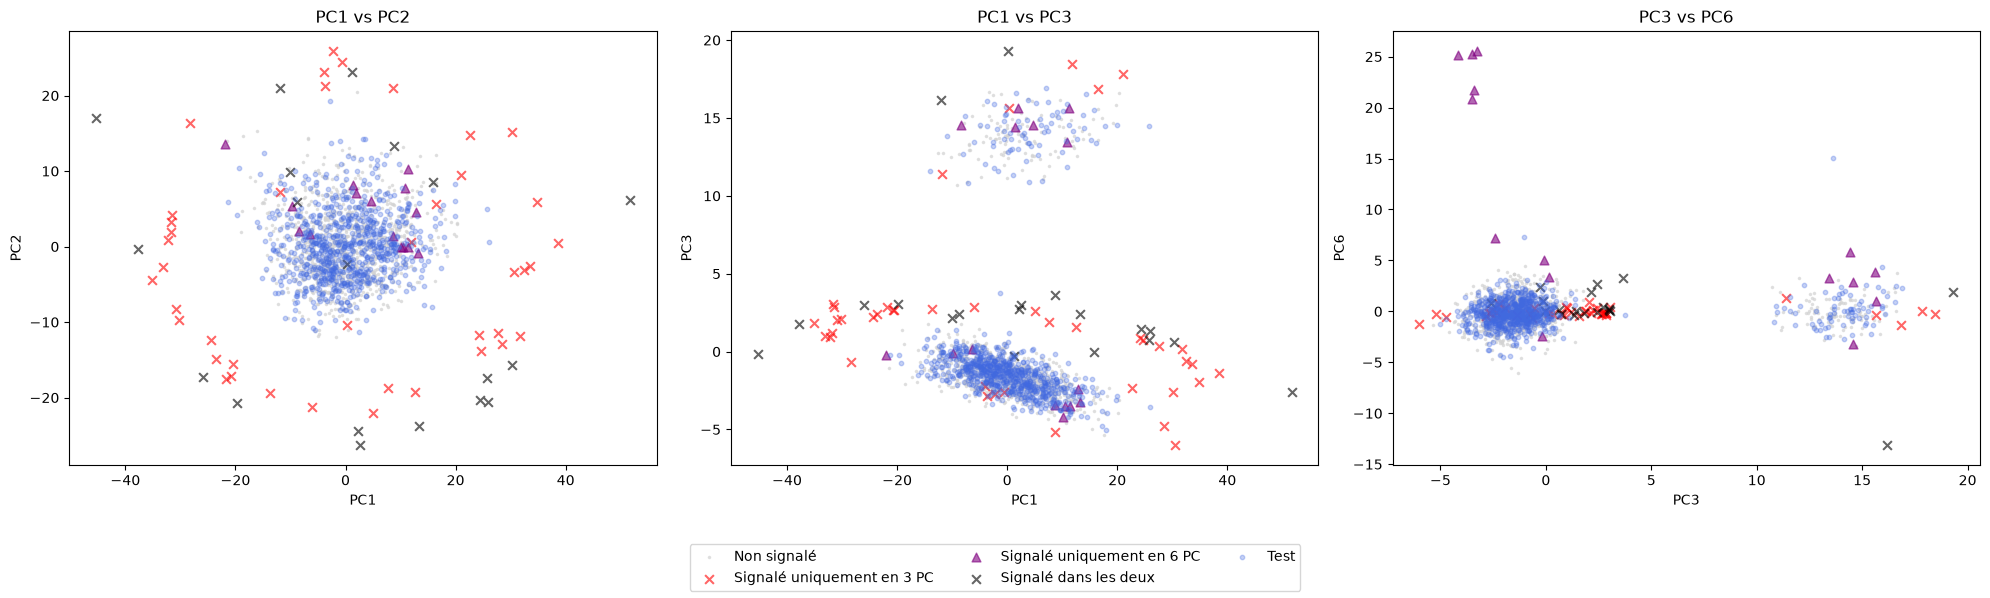

In [6]:
# Masques des deux variantes, dans l'ordre des observations du train
flag_3 = outlier_masks.loc[X_train.index, "3_PC"].to_numpy()
flag_6 = outlier_masks.loc[X_train.index, "6_PC"].to_numpy()

# Quatre groupes pour comprendre les désaccords
groups = [
    ("Non signalé", ~flag_3 & ~flag_6, "lightgrey", ".", 10),
    ("Signalé uniquement en 3 PC", flag_3 & ~flag_6, "red", "x", 40),
    ("Signalé uniquement en 6 PC", ~flag_3 & flag_6, "purple", "^", 40),
    ("Signalé dans les deux", flag_3 & flag_6, "black", "x", 40)
]

display(pd.DataFrame({
    "groupe": [name for name, *_ in groups],
    "observations": [int(mask.sum()) for _, mask, *_ in groups]
}))

# Deux vues de la structure principale et une incluant PC6
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (2, 5)]):
    for name, mask, color, marker, size in groups:
        ax.scatter(
            P_train[mask, i],
            P_train[mask, j],
            color=color,
            marker=marker,
            s=size,
            alpha=0.6,
            label=name
        )

    ax.scatter(
        P_test[:, i],
        P_test[:, j],
        color="royalblue",
        s=10,
        alpha=0.3,
        label="Test"
    )

    ax.set(
        xlabel=f"PC{i + 1}",
        ylabel=f"PC{j + 1}",
        title=f"PC{i + 1} vs PC{j + 1}"
    )

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3)
fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

Examination des candidates ajoutés par la détection en 6 PC 

In [7]:
# Observations signalées en 6 PC, mais pas en 3 PC
additional_mask = (
    outlier_masks["6_PC"] & ~outlier_masks["3_PC"]
)
additional_ids = outlier_masks.index[additional_mask]

# Écart à la médiane de chaque feature, exprimé en unités d'IQR
# Les NaN restent manquants dans ce diagnostic
medians = X_train.median()
iqr = X_train.quantile(0.75) - X_train.quantile(0.25)

deviations = (
    X_train.sub(medians)
    .div(iqr.replace(0, np.nan))
    .abs()
)

# Diagnostic pour toutes les observations
diagnostic = pd.DataFrame(index=X_train.index)

diagnostic["NaN (%)"] = 100 * X_train.isna().mean(axis=1)
diagnostic["écart_max_IQR"] = deviations.max(axis=1)
diagnostic["nb_features_écart_sup_5_IQR"] = deviations.gt(5).sum(axis=1)

diagnostic["groupe"] = "Non signalé"
diagnostic.loc[outlier_masks["3_PC"], "groupe"] = "Signalé en 3 PC"
diagnostic.loc[additional_ids, "groupe"] = "Ajouté par 6 PC"

# Comparaison des groupes
display(
    diagnostic.groupby("groupe").agg(
        observations=("NaN (%)", "size"),
        NaN_moyen_pct=("NaN (%)", "mean"),
        ecart_max_median=("écart_max_IQR", "median"),
        nb_features_extremes_moyen=("nb_features_écart_sup_5_IQR", "mean")
    ).round(2)
)

# Détail des 15 observations supplémentaires
additional_details = diagnostic.loc[additional_ids].drop(
    columns="groupe"
).copy()

additional_details["features_les_plus_atypiques"] = (
    deviations.loc[additional_ids].apply(
        lambda row: ", ".join(row.nlargest(3).index),
        axis=1
    )
)

display(
    additional_details.sort_values(
        "écart_max_IQR", ascending=False
    ).round(2)
)

,observations,NaN_moyen_pct,ecart_max_median,nb_features_extremes_moyen
groupe,,,,
Ajouté par 6 PC,15,7.42,15.47,1.67
Non signalé,1137,7.63,2.63,0.18
Signalé en 3 PC,60,7.56,4.37,1.18


,NaN (%),écart_max_IQR,nb_features_écart_sup_5_IQR,features_les_plus_atypiques
id,,,,
592.0,6.88,25.26,1,"x413, x641, x820"
806.0,7.25,25.22,1,"x413, x641, x216"
808.0,7.37,25.01,1,"x413, x746, x532"
179.0,6.88,21.85,1,"x413, x641, x49"
751.0,7.73,21.09,1,"x413, x217, x167"
1100.0,9.42,16.36,2,"x143, x742, x649"
646.0,6.52,16.20,2,"x742, x115, x413"
937.0,7.13,15.47,4,"x742, x115, x641"
788.0,8.21,14.58,2,"x143, x742, x820"


On test : 
- aucune suppression
- suppresion des 60 candidats en 3 PC 
- suppression des 34 candidats en 6 PC
- suppression de l'union des 75 

Pour isoler l'effet des outliers, on utilise les mêmes 828 features, les NaN natifs et une config XGB fixe. 
On réajuste le détecteur dans chaque fold, uniquement sur son entraînement 

In [8]:
# Découpages identiques pour les quatre stratégies
cv_outliers = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

strategies = ["Aucune suppression", "3 PC", "6 PC", "Union"]

# Configuration de référence, fixe pour cette comparaison
xgb_reference = XGBRegressor(
    objective="reg:squarederror",
    tree_method="hist",
    n_estimators=500,
    learning_rate=0.1,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.6,
    reg_alpha=1,
    reg_lambda=1,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Prédictions et résultats conservés en mémoire
oof_outliers = pd.DataFrame(
    np.nan,
    index=X_train.index,
    columns=strategies
)
fold_results = []

for fold, (tr_idx, val_idx) in enumerate(
    cv_outliers.split(X_train), start=1
):
    X_tr = X_train.iloc[tr_idx]
    X_val = X_train.iloc[val_idx]
    y_tr = y_train.iloc[tr_idx]
    y_val = y_train.iloc[val_idx]

    # Préparation temporaire pour le détecteur uniquement
    imputer_fold = SimpleImputer(strategy="median")
    A_tr = imputer_fold.fit_transform(X_tr)
    A_test = imputer_fold.transform(X_test)

    scaler_fold = RobustScaler()
    A_tr = scaler_fold.fit_transform(A_tr)
    A_test = scaler_fold.transform(A_test)

    pca_fold = PCA(n_components=6, svd_solver="full")
    P_tr = pca_fold.fit_transform(A_tr)
    P_te = pca_fold.transform(A_test)

    pc_scaler_fold = RobustScaler()
    Z_tr = pc_scaler_fold.fit_transform(P_tr)
    Z_te = pc_scaler_fold.transform(P_te)

    # Détection sur les lignes d'entraînement du fold
    flags = {}

    for n_pc in [3, 6]:
        neighbors = NearestNeighbors().fit(Z_te[:, :n_pc])

        train_distances = neighbors.kneighbors(
            Z_tr[:, :n_pc], n_neighbors=5
        )[0][:, -1]

        test_distances = neighbors.kneighbors(
            Z_te[:, :n_pc], n_neighbors=6
        )[0][:, -1]

        threshold = np.quantile(test_distances, 0.995)
        flags[n_pc] = train_distances > threshold

    masks = {
        "Aucune suppression": np.zeros(len(X_tr), dtype=bool),
        "3 PC": flags[3],
        "6 PC": flags[6],
        "Union": flags[3] | flags[6]
    }

    # XGBoost reçoit les features originales avec leurs NaN
    for strategy, remove in masks.items():
        keep_idx = np.flatnonzero(~remove)

        model = clone(xgb_reference)
        model.fit(
            X_tr.iloc[keep_idx],
            y_tr.iloc[keep_idx]
        )

        predictions = model.predict(X_val)
        oof_outliers.loc[X_val.index, strategy] = predictions

        fold_results.append({
            "strategie": strategy,
            "fold": fold,
            "observations_retirees": int(remove.sum()),
            "R2": r2_score(y_val, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_val, predictions)
            )
        })

    print(f"Fold {fold}/{N_SPLITS} terminé")

# Bilan des performances
fold_results = pd.DataFrame(fold_results)

summary_outliers = fold_results.groupby("strategie").agg(
    R2_moyen=("R2", "mean"),
    R2_ecart_type=("R2", "std"),
    RMSE_moyenne=("RMSE", "mean"),
    retraits_moyens=("observations_retirees", "mean")
)

summary_outliers["R2_OOF"] = [
    r2_score(y_train, oof_outliers[strategy])
    for strategy in summary_outliers.index
]

display(summary_outliers.sort_values("R2_OOF", ascending=False).round(4))

# Comparaison fold par fold
display(
    fold_results.pivot(
        index="fold", columns="strategie", values="R2"
    ).reindex(columns=strategies).round(4)
)

Fold 1/5 terminé
Fold 2/5 terminé
Fold 3/5 terminé
Fold 4/5 terminé
Fold 5/5 terminé


,R2_moyen,R2_ecart_type,RMSE_moyenne,retraits_moyens,R2_OOF
strategie,,,,,
Aucune suppression,0.4866,0.0592,6.9319,0.0,0.4904
6 PC,0.4690,0.0504,7.0559,27.2,0.4720
3 PC,0.4537,0.0851,7.1464,49.2,0.4570
Union,0.4483,0.0935,7.1793,61.0,0.4516


strategie,Aucune suppression,3 PC,6 PC,Union
fold,,,,
1,0.4876,0.5068,0.5035,0.4900
2,0.4854,0.4601,0.4609,0.4685
3,0.4053,0.3097,0.4059,0.2848
4,0.5726,0.5261,0.5335,0.5211
5,0.4821,0.4660,0.4414,0.4770


Feature selection, plusieurs tailles avec le même XGBoost 
In each fold, le classement Spearman est calculé uniquement sur son entraînement 

In [9]:
# Nombre de features à comparer
feature_counts = [50, 100, 150, 216, 300, X_train.shape[1]]

oof_selection = pd.DataFrame(
    np.nan,
    index=X_train.index,
    columns=feature_counts
)
selection_scores = []

# Même découpage que pour la comparaison des outliers
for fold, (tr_idx, val_idx) in enumerate(
    cv_outliers.split(X_train), start=1
):
    X_tr = X_train.iloc[tr_idx]
    X_val = X_train.iloc[val_idx]
    y_tr = y_train.iloc[tr_idx]
    y_val = y_train.iloc[val_idx]

    # Classement appris uniquement sur le train du fold
    # Spearman ignore les paires contenant un NaN
    ranking = (
        X_tr.corrwith(y_tr, method="spearman")
        .abs()
        .fillna(0)
        .sort_values(ascending=False)
    )

    for k in feature_counts:
        # Conserver l'ordre original des colonnes
        selected_columns = X_tr.columns[
            X_tr.columns.isin(ranking.index[:k])
        ]

        model = clone(xgb_reference)
        model.fit(X_tr[selected_columns], y_tr)

        predictions = model.predict(X_val[selected_columns])
        oof_selection.loc[X_val.index, k] = predictions

        selection_scores.append({
            "features": k,
            "fold": fold,
            "R2": r2_score(y_val, predictions)
        })

    print(f"Fold {fold}/{N_SPLITS} terminé")

# Bilan sur les 1 212 observations
selection_scores = pd.DataFrame(selection_scores)

summary_selection = selection_scores.groupby("features").agg(
    R2_moyen=("R2", "mean"),
    R2_ecart_type=("R2", "std")
)

summary_selection["R2_OOF_tous"] = [
    r2_score(y_train, oof_selection[k])
    for k in summary_selection.index
]

# Diagnostic supplémentaire sur les 1 152 IDs de l'ancienne préparation
reference_ids = pd.read_csv(
    DATA_DIR / "X_train_knn.csv",
    usecols=["id"]
)["id"]

summary_selection["R2_OOF_reference_1152"] = [
    r2_score(
        y_train.loc[reference_ids],
        oof_selection.loc[reference_ids, k]
    )
    for k in summary_selection.index
]

display(summary_selection.round(4))

# Stabilité des résultats entre les folds
display(
    selection_scores.pivot(
        index="fold", columns="features", values="R2"
    ).round(4)
)

Fold 1/5 terminé
Fold 2/5 terminé
Fold 3/5 terminé
Fold 4/5 terminé
Fold 5/5 terminé


,R2_moyen,R2_ecart_type,R2_OOF_tous,R2_OOF_reference_1152
features,,,,
50,0.4784,0.0351,0.4815,0.5632
100,0.4934,0.0348,0.4966,0.5840
150,0.5138,0.0361,0.5166,0.5997
216,0.5163,0.0321,0.5184,0.5972
300,0.5015,0.0500,0.5047,0.5824
828,0.4866,0.0592,0.4904,0.5663


features,50,100,150,216,300,828
fold,,,,,,
1,0.4914,0.4881,0.5183,0.5374,0.5244,0.4876
2,0.4284,0.4654,0.5071,0.5106,0.4877,0.4854
3,0.4649,0.4593,0.4668,0.4632,0.4292,0.4053
4,0.5236,0.5446,0.5678,0.5424,0.5651,0.5726
5,0.4839,0.5095,0.5087,0.5281,0.5012,0.4821


Combinaison de feature selection et suppression des outliers 

In [10]:
# Détection réajustée sur le train de chaque fold
def detect_outliers_fold(X_fit, X_reference):
    imputer = SimpleImputer(strategy="median")
    A_fit = imputer.fit_transform(X_fit)
    A_reference = imputer.transform(X_reference)

    scaler = RobustScaler()
    A_fit = scaler.fit_transform(A_fit)
    A_reference = scaler.transform(A_reference)

    pca = PCA(n_components=6, svd_solver="full")
    P_fit = pca.fit_transform(A_fit)
    P_reference = pca.transform(A_reference)

    pc_scaler = RobustScaler()
    Z_fit = pc_scaler.fit_transform(P_fit)
    Z_reference = pc_scaler.transform(P_reference)

    flags = {}

    for n_pc in [3, 6]:
        neighbors = NearestNeighbors().fit(Z_reference[:, :n_pc])

        fit_distances = neighbors.kneighbors(
            Z_fit[:, :n_pc], n_neighbors=5
        )[0][:, -1]

        reference_distances = neighbors.kneighbors(
            Z_reference[:, :n_pc], n_neighbors=6
        )[0][:, -1]

        threshold = np.quantile(reference_distances, 0.995)
        flags[n_pc] = fit_distances > threshold

    return {
        "Aucune suppression": np.zeros(len(X_fit), dtype=bool),
        "3 PC": flags[3],
        "6 PC": flags[6],
        "Union": flags[3] | flags[6]
    }


# Configurations à comparer
selected_counts = [150, 216]
strategies = ["Aucune suppression", "3 PC", "6 PC", "Union"]

oof_clean_selection = {
    (strategy, k): pd.Series(np.nan, index=X_train.index)
    for strategy in strategies
    for k in selected_counts
}

clean_selection_scores = []

for fold, (tr_idx, val_idx) in enumerate(
    cv_outliers.split(X_train), start=1
):
    X_tr = X_train.iloc[tr_idx]
    X_val = X_train.iloc[val_idx]
    y_tr = y_train.iloc[tr_idx]
    y_val = y_train.iloc[val_idx]

    # Le test sert toujours de référence géométrique
    fold_masks = detect_outliers_fold(X_tr, X_test)

    for strategy, remove in fold_masks.items():
        keep_idx = np.flatnonzero(~remove)

        X_fit = X_tr.iloc[keep_idx]
        y_fit = y_tr.iloc[keep_idx]

        # Sélection après suppression, sur le train conservé uniquement
        ranking = (
            X_fit.corrwith(y_fit, method="spearman")
            .abs()
            .fillna(0)
            .sort_values(ascending=False)
        )

        for k in selected_counts:
            columns = X_fit.columns[
                X_fit.columns.isin(ranking.index[:k])
            ]

            model = clone(xgb_reference)
            model.fit(X_fit[columns], y_fit)

            predictions = model.predict(X_val[columns])

            oof_clean_selection[(strategy, k)].iloc[val_idx] = predictions

            clean_selection_scores.append({
                "strategie": strategy,
                "features": k,
                "fold": fold,
                "observations_retirees": int(remove.sum()),
                "R2": r2_score(y_val, predictions)
            })

    print(f"Fold {fold}/{N_SPLITS} terminé")


# Résumé par configuration
clean_selection_scores = pd.DataFrame(clean_selection_scores)

summary_clean_selection = clean_selection_scores.groupby(
    ["strategie", "features"]
).agg(
    R2_moyen=("R2", "mean"),
    R2_ecart_type=("R2", "std"),
    retraits_moyens=("observations_retirees", "mean")
)

summary_clean_selection["R2_OOF_tous"] = [
    r2_score(y_train, oof_clean_selection[key])
    for key in summary_clean_selection.index
]

# Même population de référence que dans la comparaison précédente
reference_ids = pd.read_csv(
    DATA_DIR / "X_train_knn.csv", usecols=["id"]
)["id"]

summary_clean_selection["R2_OOF_reference_1152"] = [
    r2_score(
        y_train.loc[reference_ids],
        oof_clean_selection[key].loc[reference_ids]
    )
    for key in summary_clean_selection.index
]

display(
    summary_clean_selection.sort_values(
        "R2_OOF_reference_1152", ascending=False
    ).round(4)
)

# Détail pour vérifier la stabilité des écarts
display(
    clean_selection_scores.pivot(
        index="fold",
        columns=["strategie", "features"],
        values="R2"
    ).round(4)
)

Fold 1/5 terminé
Fold 2/5 terminé
Fold 3/5 terminé
Fold 4/5 terminé
Fold 5/5 terminé


R2_moyen  R2_ecart_type  retraits_moyens  \
strategie          features                                             
3 PC               216         0.4876         0.0946             49.2   
Union              216         0.4688         0.0880             61.0   
                   150         0.4712         0.0840             61.0   
3 PC               150         0.4698         0.0867             49.2   
6 PC               150         0.5059         0.0273             27.2   
Aucune suppression 150         0.5138         0.0361              0.0   
                   216         0.5163         0.0321              0.0   
6 PC               216         0.5030         0.0470             27.2   

                             R2_OOF_tous  R2_OOF_reference_1152  
strategie          features                                      
3 PC               216            0.4886                 0.6191  
Union              216            0.4721                 0.6130  
                   150            0.4733                 0.6069  
3 PC               150            0.4725                 0.6064  
6 PC               150            0.5081                 0.6036  
Aucune suppression 150            0.5166                 0.5997  
                   216            0.5184                 0.5972  
6 PC               216            0.5046                 0.5819

strategie Aucune suppression            3 PC            6 PC           Union  \
features                 150     216     150     216     150     216     150   
fold                                                                           
1                     0.5183  0.5374  0.5204  0.5783  0.5104  0.5620  0.5246   
2                     0.5071  0.5106  0.4938  0.5312  0.5117  0.5066  0.4997   
3                     0.4668  0.4632  0.3171  0.3284  0.4649  0.4341  0.3219   
4                     0.5678  0.5424  0.5260  0.4984  0.5410  0.5233  0.5058   
5                     0.5087  0.5281  0.4915  0.5017  0.5016  0.4891  0.5038   

strategie          
features      216  
fold               
1          0.5060  
2          0.4829  
3          0.3161  
4          0.5413  
5          0.4974

Comparaison entre NaN natifs, médiane et KNN à 5 voisins, avec 216 features et deux stratégies : aucune suppression ou suppresion en 3PC 

In [11]:
strategies_imputation = ["Aucune suppression", "3 PC"]
imputation_methods = ["NaN natifs", "Médiane", "KNN"]

reference_ids = pd.Index(
    pd.read_csv(DATA_DIR / "X_train_knn.csv", usecols=["id"])["id"]
)

oof_imputation = {
    (strategy, method): pd.Series(np.nan, index=X_train.index)
    for strategy in strategies_imputation
    for method in imputation_methods
}

imputation_scores = []

for fold, (tr_idx, val_idx) in enumerate(
    cv_outliers.split(X_train), start=1
):
    X_tr = X_train.iloc[tr_idx]
    X_val = X_train.iloc[val_idx]
    y_tr = y_train.iloc[tr_idx]
    y_val = y_train.iloc[val_idx]

    fold_masks = detect_outliers_fold(X_tr, X_test)

    for strategy in strategies_imputation:
        keep_idx = np.flatnonzero(~fold_masks[strategy])

        X_fit = X_tr.iloc[keep_idx]
        y_fit = y_tr.iloc[keep_idx]

        # Sélection sur les observations conservées
        ranking = (
            X_fit.corrwith(y_fit, method="spearman")
            .abs()
            .fillna(0)
            .sort_values(ascending=False)
        )

        columns = X_fit.columns[
            X_fit.columns.isin(ranking.index[:216])
        ]

        X_fit_selected = X_fit[columns]
        X_val_selected = X_val[columns]

        # 1. Médiane : statistiques du train conservé uniquement
        medians_fold = X_fit_selected.median()

        # 2. KNN : standardiser pour calculer les distances
        scaler_knn = StandardScaler()
        Z_fit = scaler_knn.fit_transform(X_fit_selected)
        Z_val = scaler_knn.transform(X_val_selected)

        imputer_knn = KNNImputer(
            n_neighbors=5,
            weights="distance"
        )

        filled_fit = scaler_knn.inverse_transform(
            imputer_knn.fit_transform(Z_fit)
        )
        filled_val = scaler_knn.inverse_transform(
            imputer_knn.transform(Z_val)
        )

        # Remplacer uniquement les NaN, préserver les valeurs observées
        X_fit_knn = X_fit_selected.fillna(
            pd.DataFrame(
                filled_fit,
                index=X_fit_selected.index,
                columns=columns
            )
        )
        X_val_knn = X_val_selected.fillna(
            pd.DataFrame(
                filled_val,
                index=X_val_selected.index,
                columns=columns
            )
        )

        datasets = {
            "NaN natifs": (X_fit_selected, X_val_selected),
            "Médiane": (
                X_fit_selected.fillna(medians_fold),
                X_val_selected.fillna(medians_fold)
            ),
            "KNN": (X_fit_knn, X_val_knn)
        }

        for method, (X_fit_ready, X_val_ready) in datasets.items():
            model = clone(xgb_reference)
            model.fit(X_fit_ready, y_fit)

            predictions = pd.Series(
                model.predict(X_val_ready),
                index=X_val.index
            )

            oof_imputation[(strategy, method)].loc[
                X_val.index
            ] = predictions

            # Score par fold sur la population de référence
            reference_val_ids = X_val.index[
                X_val.index.isin(reference_ids)
            ]

            imputation_scores.append({
                "strategie": strategy,
                "imputation": method,
                "fold": fold,
                "R2_reference": r2_score(
                    y_val.loc[reference_val_ids],
                    predictions.loc[reference_val_ids]
                )
            })

    print(f"Fold {fold}/{N_SPLITS} terminé")


# Tableau principal : les deux populations d'évaluation
summary_imputation = pd.DataFrame([
    {
        "strategie": strategy,
        "imputation": method,
        "R2_OOF_reference_1152": r2_score(
            y_train.loc[reference_ids],
            predictions.loc[reference_ids]
        ),
        "R2_OOF_tous": r2_score(y_train, predictions)
    }
    for (strategy, method), predictions in oof_imputation.items()
]).set_index(["strategie", "imputation"])

display(
    summary_imputation.sort_values(
        "R2_OOF_reference_1152", ascending=False
    ).round(4)
)

# Stabilité sur les folds, pour la même population de référence
imputation_scores = pd.DataFrame(imputation_scores)

display(
    imputation_scores.pivot(
        index="fold",
        columns=["strategie", "imputation"],
        values="R2_reference"
    ).round(4)
)

Fold 1/5 terminé
Fold 2/5 terminé
Fold 3/5 terminé
Fold 4/5 terminé
Fold 5/5 terminé


R2_OOF_reference_1152  R2_OOF_tous
strategie          imputation                                    
3 PC               KNN                        0.6476       0.5004
Aucune suppression KNN                        0.6335       0.5276
3 PC               Médiane                    0.6277       0.4960
                   NaN natifs                 0.6191       0.4886
Aucune suppression Médiane                    0.6069       0.5207
                   NaN natifs                 0.5972       0.5184

strategie  Aucune suppression                       3 PC                
imputation         NaN natifs Médiane     KNN NaN natifs Médiane     KNN
fold                                                                    
1                      0.6235  0.6377  0.6697     0.6967  0.6757  0.7029
2                      0.6364  0.6315  0.6565     0.6692  0.6613  0.6713
3                      0.5034  0.4815  0.5582     0.5141  0.5102  0.5557
4                      0.6186  0.6720  0.6405     0.6131  0.6445  0.6644
5                      0.5983  0.6009  0.6377     0.6016  0.6414  0.6388

In [13]:
oof_log_knn = pd.Series(
    np.nan, index=X_train.index, name="log_signe_knn"
)

log_comparison_folds = []
log_columns_by_fold = {}

baseline_knn = oof_imputation[("3 PC", "KNN")]

for fold, (tr_idx, val_idx) in enumerate(
    cv_outliers.split(X_train), start=1
):
    X_tr = X_train.iloc[tr_idx]
    X_val = X_train.iloc[val_idx]
    y_tr = y_train.iloc[tr_idx]
    y_val = y_train.iloc[val_idx]

    # Détection inchangée, sur les données originales
    fold_masks = detect_outliers_fold(X_tr, X_test)
    keep_idx = np.flatnonzero(~fold_masks["3 PC"])

    X_fit = X_tr.iloc[keep_idx]
    y_fit = y_tr.iloc[keep_idx]

    # Sélection sur le train conservé uniquement
    ranking = (
        X_fit.corrwith(y_fit, method="spearman")
        .abs()
        .fillna(0)
        .sort_values(ascending=False)
    )

    columns = X_fit.columns[
        X_fit.columns.isin(ranking.index[:216])
    ]

    X_fit_log = X_fit[columns].copy()
    X_val_log = X_val[columns].copy()

    # Choix des colonnes sur le train conservé uniquement
    log_columns = X_fit_log.columns[
        (X_fit_log.skew() > 1)
        & (X_fit_log.min() > 0)
    ]
    log_columns_by_fold[fold] = log_columns.tolist()

    # Log signé : accepte aussi les valeurs négatives en validation
    # Les NaN sont conservés jusqu'à l'imputation
    X_fit_log[log_columns] = (
        np.sign(X_fit_log[log_columns])
        * np.log1p(X_fit_log[log_columns].abs())
    )
    X_val_log[log_columns] = (
        np.sign(X_val_log[log_columns])
        * np.log1p(X_val_log[log_columns].abs())
    )

    # Standardisation puis KNN dans l'espace transformé
    scaler = StandardScaler()
    Z_fit = scaler.fit_transform(X_fit_log)
    Z_val = scaler.transform(X_val_log)

    imputer = KNNImputer(
        n_neighbors=5,
        weights="distance"
    )

    filled_fit = scaler.inverse_transform(
        imputer.fit_transform(Z_fit)
    )
    filled_val = scaler.inverse_transform(
        imputer.transform(Z_val)
    )

    # Remplacer uniquement les valeurs manquantes
    X_fit_ready = X_fit_log.fillna(
        pd.DataFrame(
            filled_fit,
            index=X_fit_log.index,
            columns=columns
        )
    )
    X_val_ready = X_val_log.fillna(
        pd.DataFrame(
            filled_val,
            index=X_val_log.index,
            columns=columns
        )
    )

    model = clone(xgb_reference)
    model.fit(X_fit_ready, y_fit)

    predictions = pd.Series(
        model.predict(X_val_ready),
        index=X_val.index
    )
    oof_log_knn.loc[X_val.index] = predictions

    reference_val_ids = X_val.index[
        X_val.index.isin(reference_ids)
    ]

    baseline_score = r2_score(
        y_val.loc[reference_val_ids],
        baseline_knn.loc[reference_val_ids]
    )
    log_score = r2_score(
        y_val.loc[reference_val_ids],
        predictions.loc[reference_val_ids]
    )

    log_comparison_folds.append({
        "fold": fold,
        "features_log": len(log_columns),
        "R2_KNN": baseline_score,
        "R2_log_signe_KNN": log_score,
        "gain": log_score - baseline_score
    })

    print(f"Fold {fold}/{N_SPLITS} terminé")


# Comparaison globale
comparison_log = pd.DataFrame({
    name: {
        "R2_OOF_reference_1152": r2_score(
            y_train.loc[reference_ids],
            predictions.loc[reference_ids]
        ),
        "R2_OOF_tous": r2_score(y_train, predictions)
    }
    for name, predictions in {
        "KNN": baseline_knn,
        "Log signé + KNN": oof_log_knn
    }.items()
}).T

display(comparison_log.round(4))

# Comparaison fold par fold sur la population de référence
log_comparison_folds = pd.DataFrame(
    log_comparison_folds
).set_index("fold")

display(log_comparison_folds.round(4))

Fold 1/5 terminé
Fold 2/5 terminé
Fold 3/5 terminé
Fold 4/5 terminé
Fold 5/5 terminé


,R2_OOF_reference_1152,R2_OOF_tous
KNN,0.6476,0.5004
Log signé + KNN,0.6580,0.5198


,features_log,R2_KNN,R2_log_signe_KNN,gain
fold,,,,
1,13,0.7029,0.7225,0.0195
2,12,0.6713,0.6844,0.0131
3,11,0.5557,0.5648,0.0091
4,11,0.6644,0.6609,-0.0036
5,11,0.6388,0.6543,0.0156


Hyperparameter tuning

In [14]:
# Chaque fold conserve sa propre préparation,
# apprise uniquement sur son entraînement
tuning_folds = []
tuning_fold_summary = []

for fold, (tr_idx, val_idx) in enumerate(
    cv_outliers.split(X_train), start=1
):
    X_tr = X_train.iloc[tr_idx]
    X_val = X_train.iloc[val_idx]
    y_tr = y_train.iloc[tr_idx]
    y_val = y_train.iloc[val_idx]

    # 1. Détection et suppression des candidats en 3 PC
    fold_masks = detect_outliers_fold(X_tr, X_test)
    keep_idx = np.flatnonzero(~fold_masks["3 PC"])

    X_fit = X_tr.iloc[keep_idx]
    y_fit = y_tr.iloc[keep_idx]

    # 2. Sélection des 216 features
    ranking = (
        X_fit.corrwith(y_fit, method="spearman")
        .abs()
        .fillna(0)
        .sort_values(ascending=False)
    )

    columns = X_fit.columns[
        X_fit.columns.isin(ranking.index[:216])
    ]

    X_fit_log = X_fit[columns].copy()
    X_val_log = X_val[columns].copy()

    # 3. Log signé : règle apprise sur le train conservé
    log_columns = X_fit_log.columns[
        (X_fit_log.skew() > 1)
        & (X_fit_log.min() > 0)
    ]

    X_fit_log[log_columns] = (
        np.sign(X_fit_log[log_columns])
        * np.log1p(X_fit_log[log_columns].abs())
    )
    X_val_log[log_columns] = (
        np.sign(X_val_log[log_columns])
        * np.log1p(X_val_log[log_columns].abs())
    )

    # 4. Standardisation et imputation KNN
    scaler = StandardScaler()
    Z_fit = scaler.fit_transform(X_fit_log)
    Z_val = scaler.transform(X_val_log)

    imputer = KNNImputer(
        n_neighbors=5,
        weights="distance"
    )

    filled_fit = scaler.inverse_transform(
        imputer.fit_transform(Z_fit)
    )
    filled_val = scaler.inverse_transform(
        imputer.transform(Z_val)
    )

    X_fit_ready = X_fit_log.fillna(
        pd.DataFrame(
            filled_fit,
            index=X_fit_log.index,
            columns=columns
        )
    )
    X_val_ready = X_val_log.fillna(
        pd.DataFrame(
            filled_val,
            index=X_val_log.index,
            columns=columns
        )
    )

    # Observations de référence à utiliser pour le score principal
    reference_mask = X_val.index.isin(reference_ids)

    # Conserver les données préparées pour la recherche
    tuning_folds.append({
        "fold": fold,
        "X_fit": X_fit_ready,
        "y_fit": y_fit.copy(),
        "X_val": X_val_ready,
        "y_val": y_val.copy(),
        "reference_mask": reference_mask
    })

    tuning_fold_summary.append({
        "fold": fold,
        "train_conserve": len(X_fit_ready),
        "observations_retirees": int(fold_masks["3 PC"].sum()),
        "validation_totale": len(X_val_ready),
        "validation_reference": int(reference_mask.sum()),
        "features": len(columns),
        "features_log": len(log_columns)
    })

display(pd.DataFrame(tuning_fold_summary).set_index("fold"))

,train_conserve,observations_retirees,validation_totale,validation_reference,features,features_log
fold,,,,,,
1,918,51,243,234,216,13
2,920,49,243,230,216,12
3,917,53,242,232,216,11
4,926,44,242,228,216,11
5,921,49,242,228,216,11


In [15]:
from sklearn.model_selection import ParameterSampler

# Première recherche conjointe
param_space = {
    "n_estimators": [300, 500, 800, 1200, 1800],
    "learning_rate": [0.015, 0.03, 0.05, 0.08, 0.1],
    "max_depth": [2, 3, 4, 5],
    "min_child_weight": [1, 3, 5, 10, 20],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.4, 0.6, 0.8, 1.0],
    "reg_lambda": [0.1, 1, 5, 20, 100],
    "reg_alpha": [0, 0.1, 1, 5],
    "gamma": [0, 0.1, 1, 5]
}

N_TRIALS = 40

# Inclure explicitement la configuration actuelle comme essai 0
reference_params = {
    name: xgb_reference.get_params()[name]
    for name in param_space
}
if reference_params["gamma"] is None:
    reference_params["gamma"] = 0

candidates = [reference_params] + list(
    ParameterSampler(
        param_space,
        n_iter=N_TRIALS,
        random_state=RANDOM_STATE
    )
)

tuning_records = []
tuning_oof = {}
tuning_fold_scores = []

for trial, params in enumerate(candidates):
    oof_trial = pd.Series(np.nan, index=X_train.index)
    reference_fold_scores = []

    for data in tuning_folds:
        model = clone(xgb_reference).set_params(**params)

        model.fit(data["X_fit"], data["y_fit"])

        predictions = pd.Series(
            model.predict(data["X_val"]),
            index=data["X_val"].index
        )

        oof_trial.loc[predictions.index] = predictions

        reference_mask = data["reference_mask"]

        fold_score = r2_score(
            data["y_val"].iloc[reference_mask],
            predictions.iloc[reference_mask]
        )
        reference_fold_scores.append(fold_score)

        tuning_fold_scores.append({
            "essai": trial,
            "fold": data["fold"],
            "R2_reference": fold_score
        })

    # Critère principal : un seul R² sur les 1 152 OOF de référence
    reference_score = r2_score(
        y_train.loc[reference_ids],
        oof_trial.loc[reference_ids]
    )

    tuning_records.append({
        "essai": trial,
        "R2_OOF_reference_1152": reference_score,
        "R2_OOF_tous": r2_score(y_train, oof_trial),
        "ecart_type_folds_reference": np.std(
            reference_fold_scores, ddof=1
        ),
        **params
    })

    tuning_oof[trial] = oof_trial

    label = "Référence" if trial == 0 else f"Essai {trial}/{N_TRIALS}"
    print(f"{label} | R² OOF référence : {reference_score:.5f}")


# Classer les configurations
tuning_results = (
    pd.DataFrame(tuning_records)
    .set_index("essai")
    .sort_values("R2_OOF_reference_1152", ascending=False)
)

tuning_fold_scores = pd.DataFrame(tuning_fold_scores)

best_trial = int(tuning_results.index[0])
best_xgb_params = candidates[best_trial].copy()
best_xgb_oof = tuning_oof[best_trial].copy()

baseline_score = tuning_results.loc[0, "R2_OOF_reference_1152"]
best_score = tuning_results.loc[
    best_trial, "R2_OOF_reference_1152"
]

print(f"\nR² référence : {baseline_score:.5f}")
print(f"Meilleur R²  : {best_score:.5f}")
print(f"Gain         : {best_score - baseline_score:+.5f}")
print("Meilleurs paramètres :", best_xgb_params)

display(tuning_results.head(10).round(5))

# Comparer le meilleur essai à la référence dans chaque fold
display(
    tuning_fold_scores[
        tuning_fold_scores["essai"].isin([0, best_trial])
    ].pivot(
        index="fold",
        columns="essai",
        values="R2_reference"
    ).round(5)
)

Référence | R² OOF référence : 0.65803
Essai 1/40 | R² OOF référence : 0.62903
Essai 2/40 | R² OOF référence : 0.64762
Essai 3/40 | R² OOF référence : 0.66484
Essai 4/40 | R² OOF référence : 0.65757
Essai 5/40 | R² OOF référence : 0.64250
Essai 6/40 | R² OOF référence : 0.63380
Essai 7/40 | R² OOF référence : 0.65343
Essai 8/40 | R² OOF référence : 0.64740
Essai 9/40 | R² OOF référence : 0.64844
Essai 10/40 | R² OOF référence : 0.65362
Essai 11/40 | R² OOF référence : 0.64244
Essai 12/40 | R² OOF référence : 0.66670
Essai 13/40 | R² OOF référence : 0.64247
Essai 14/40 | R² OOF référence : 0.65938
Essai 15/40 | R² OOF référence : 0.65529
Essai 16/40 | R² OOF référence : 0.63324
Essai 17/40 | R² OOF référence : 0.65474
Essai 18/40 | R² OOF référence : 0.64366
Essai 19/40 | R² OOF référence : 0.65612
Essai 20/40 | R² OOF référence : 0.64842
Essai 21/40 | R² OOF référence : 0.63592
Essai 22/40 | R² OOF référence : 0.63880
Essai 23/40 | R² OOF référence : 0.65625
Essai 24/40 | R² OOF référe

,R2_OOF_reference_1152,R2_OOF_tous,ecart_type_folds_reference,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma
essai,,,,,,,,,,,,
12,0.66670,0.53040,0.06106,1200,0.030,4,20,0.6,1.0,0.1,1.0,1.0
3,0.66484,0.54220,0.05081,1200,0.030,5,20,0.8,0.6,5.0,5.0,0.0
31,0.66434,0.53976,0.05923,1800,0.015,4,10,0.6,0.6,5.0,1.0,5.0
32,0.66131,0.56431,0.05542,1800,0.015,5,1,0.6,0.6,20.0,1.0,1.0
14,0.65938,0.52619,0.05940,800,0.050,3,20,0.6,1.0,5.0,5.0,0.0
33,0.65836,0.53354,0.05259,300,0.050,5,10,0.8,0.8,1.0,5.0,5.0
0,0.65803,0.51982,0.05821,500,0.100,3,5,0.8,0.6,1.0,1.0,0.0
4,0.65757,0.52516,0.06234,800,0.015,5,20,0.6,1.0,1.0,0.1,0.0
23,0.65625,0.54458,0.05626,1800,0.080,4,5,0.6,0.8,20.0,1.0,1.0


essai,0,12
fold,,
1,0.72245,0.70832
2,0.68438,0.70815
3,0.56482,0.56063
4,0.66089,0.68005
5,0.65433,0.67268


In [16]:
# Population et découpage de l'ancien XGBoost
shared_folds = pd.read_csv(
    DATA_DIR / "Stacking" / "folds.csv",
    index_col="id"
)["fold"]

X_compare = X_train_raw.loc[shared_folds.index].drop(
    columns=constant_cols
).copy()
y_compare = y_raw.loc[X_compare.index]

methods = ["KNN", "Log signé + KNN"]

paired_oof = pd.DataFrame(
    np.nan,
    index=X_compare.index,
    columns=methods
)
paired_fold_scores = []


# Imputation ajustée uniquement sur le train reçu
def prepare_knn_pair(X_fit, X_valid):
    scaler = StandardScaler()
    Z_fit = scaler.fit_transform(X_fit)
    Z_valid = scaler.transform(X_valid)

    imputer = KNNImputer(
        n_neighbors=5,
        weights="distance"
    )

    filled_fit = scaler.inverse_transform(
        imputer.fit_transform(Z_fit)
    )
    filled_valid = scaler.inverse_transform(
        imputer.transform(Z_valid)
    )

    X_fit_ready = X_fit.fillna(
        pd.DataFrame(
            filled_fit,
            index=X_fit.index,
            columns=X_fit.columns
        )
    )
    X_valid_ready = X_valid.fillna(
        pd.DataFrame(
            filled_valid,
            index=X_valid.index,
            columns=X_valid.columns
        )
    )

    return X_fit_ready, X_valid_ready


for fold in sorted(shared_folds.unique()):
    train = shared_folds != fold
    valid = shared_folds == fold

    X_fit = X_compare.loc[train]
    X_valid = X_compare.loc[valid]
    y_fit = y_compare.loc[train]
    y_valid = y_compare.loc[valid]

    # Même sélection pour les deux variantes, apprise dans le fold
    ranking = (
        X_fit.corrwith(y_fit, method="spearman")
        .abs()
        .fillna(0)
        .sort_values(ascending=False)
    )

    columns = X_fit.columns[
        X_fit.columns.isin(ranking.index[:216])
    ]

    X_fit_selected = X_fit[columns].copy()
    X_valid_selected = X_valid[columns].copy()

    log_columns = X_fit_selected.columns[
        (X_fit_selected.skew() > 1)
        & (X_fit_selected.min() > 0)
    ]

    for method in methods:
        X_fit_method = X_fit_selected.copy()
        X_valid_method = X_valid_selected.copy()

        if method == "Log signé + KNN":
            X_fit_method[log_columns] = (
                np.sign(X_fit_method[log_columns])
                * np.log1p(X_fit_method[log_columns].abs())
            )
            X_valid_method[log_columns] = (
                np.sign(X_valid_method[log_columns])
                * np.log1p(X_valid_method[log_columns].abs())
            )

        X_fit_ready, X_valid_ready = prepare_knn_pair(
            X_fit_method, X_valid_method
        )

        # Paramètres identiques pour les deux recettes
        model = clone(xgb_reference)
        model.fit(X_fit_ready, y_fit)

        predictions = model.predict(X_valid_ready)
        paired_oof.loc[X_valid.index, method] = predictions

        paired_fold_scores.append({
            "fold": fold,
            "methode": method,
            "R2": r2_score(y_valid, predictions)
        })

    print(f"Fold {fold + 1}/{shared_folds.nunique()} terminé")


# Comparaison globale sur les mêmes 1 152 observations
paired_summary = pd.DataFrame({
    method: {
        "R2_OOF": r2_score(y_compare, paired_oof[method]),
        "RMSE": np.sqrt(
            mean_squared_error(y_compare, paired_oof[method])
        )
    }
    for method in methods
}).T

display(paired_summary.round(5))

# Comparaison directe dans chaque fold
paired_fold_table = pd.DataFrame(paired_fold_scores).pivot(
    index="fold",
    columns="methode",
    values="R2"
)

paired_fold_table["gain_log"] = (
    paired_fold_table["Log signé + KNN"]
    - paired_fold_table["KNN"]
)

display(paired_fold_table.round(5))

# Ancien résultat, affiché comme repère historique
historical_oof = pd.read_csv(
    DATA_DIR / "Stacking" / "oof_xgb.csv",
    index_col="id"
).iloc[:, 0].loc[X_compare.index]

print(
    "\nR² historique — sélection et imputation avant CV : "
    f"{r2_score(y_compare, historical_oof):.5f}"
)

Fold 1/5 terminé
Fold 2/5 terminé
Fold 3/5 terminé
Fold 4/5 terminé
Fold 5/5 terminé


,R2_OOF,RMSE
KNN,0.65277,5.51887
Log signé + KNN,0.65370,5.51141


methode,KNN,Log signé + KNN,gain_log
fold,,,
0,0.66960,0.65997,-0.00963
1,0.65847,0.65106,-0.00741
2,0.62983,0.65002,0.02019
3,0.63224,0.63889,0.00664
4,0.66893,0.66567,-0.00326



R² historique — sélection et imputation avant CV : 0.67872
